The task in this notebook is to train a network which, given an image of a star, will calculate both the number of points on the star, as well as its width.

Thus this will be a multi-task network, performing two completely different tasks simultaneously.


In [34]:
#%% import stuff:

import matplotlib.pyplot as plt
import numpy as np
import pickle

import torch
import torch.nn as nn

The cell below assumes you have already downloaded the dataset from brightspace, and put it in your google drive folder. It demonstrates how to use google drive together with a colab notebook.

In [35]:
temp=pickle.load(open('starData.p','rb'))
X=temp['X']
y=temp['y']

In [36]:
X.shape

torch.Size([2000, 1, 100, 100])

tensor([5.0000, 3.1239])


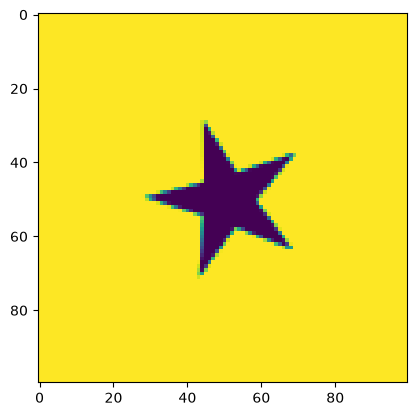

In [37]:
#Let's plot an example
idx=125
plt.imshow(np.squeeze(X[125,:,:,:],axis=0))
print(y[idx,:]) #first column is number of points, second is size of the star

In [38]:
np.squeeze(X[125,:,:,:],axis=0).shape

torch.Size([100, 100])

In [39]:
#%% make datasets & loaders

#split in val and train
N = X.shape[0]
train_X = X[:int(N*0.8),:,:,:]
train_y = y[:int(N*0.8),:]
val_x = X[int(N*0.8):,:,:,:]
val_y = y[int(N*0.8):,:]

#make datasets (TensorDataset will do)
training_set = torch.utils.data.TensorDataset(train_X, train_y)
validation_set = torch.utils.data.TensorDataset(val_x, val_y)

#make dataloaders
trainLoader = torch.utils.data.DataLoader(training_set, batch_size=32, shuffle=True)
valLoader = torch.utils.data.DataLoader(validation_set, batch_size=32, shuffle=False)


In [40]:
#%% make network

#something simple like cnn-cnn-fc-relu-fc will do
class someNetwork(nn.Module):
    def __init__(self):
        super(someNetwork, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.fc1 = nn.Linear(64 * 25 * 25, 128)  # Assuming input size is 100x100
        self.fc2 = nn.Linear(128, 2)  # Output two values: number of points and size of the star
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)  # Flatten the tensor
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x


#testing:
testData=torch.rand((1,1,100,100))
testNet=someNetwork()
testNet.forward(testData)

tensor([[0.0504, 0.0265]], grad_fn=<AddmmBackward0>)

In [41]:
#%% define loss'es
loss1=nn.MSELoss() #for the number of points
loss2=nn.MSELoss() #for the size of the star
loss_fn = lambda output, target: loss1(output[:, 0], target[:, 0]) + loss2(output[:, 1], target[:, 1])

In [43]:
#%% train & validate

nEpoch=10

net=someNetwork()
optimizer=torch.optim.AdamW(net.parameters(), lr=0.001)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
net.to(device)
trainLoader = [(xbatch.to(device), ybatch.to(device)) for xbatch, ybatch in trainLoader]
valLoader = [(xbatch.to(device), ybatch.to(device)) for xbatch, ybatch in valLoader]

for iEpoch in range(nEpoch):

    totLoss=0
    for xbatch,ybatch in trainLoader:
        optimizer.zero_grad()
        output=net(xbatch)
        loss=loss_fn(output,ybatch)
        loss.backward()
        optimizer.step()
        totLoss+=loss.item()

    print(f"Epoch {iEpoch+1}/{nEpoch}, Training Loss: {totLoss/len(trainLoader)}")

    for xbatch,ybatch in valLoader:
        output=net(xbatch)
        loss=loss_fn(output,ybatch)

    print(f"Epoch {iEpoch+1}/{nEpoch}, Validation Loss: {loss.item()}")




Epoch 1/10, Training Loss: 62197.447374339106
Epoch 1/10, Validation Loss: 2.518761396408081
Epoch 2/10, Training Loss: 2.183459613323212
Epoch 2/10, Validation Loss: 1.2588104009628296
Epoch 3/10, Training Loss: 1.0195552897453308
Epoch 3/10, Validation Loss: 0.5770541429519653
Epoch 4/10, Training Loss: 0.5623720890283584
Epoch 4/10, Validation Loss: 0.3414793610572815
Epoch 5/10, Training Loss: 0.37957523614168165
Epoch 5/10, Validation Loss: 0.23153521120548248
Epoch 6/10, Training Loss: 0.2822094136476517
Epoch 6/10, Validation Loss: 0.18769729137420654
Epoch 7/10, Training Loss: 0.22159608125686645
Epoch 7/10, Validation Loss: 0.14579758048057556
Epoch 8/10, Training Loss: 0.18168578192591667
Epoch 8/10, Validation Loss: 0.12147784233093262
Epoch 9/10, Training Loss: 0.15419401720166206
Epoch 9/10, Validation Loss: 0.1078115701675415
Epoch 10/10, Training Loss: 0.13412971027195453
Epoch 10/10, Validation Loss: 0.1008540540933609


Text(0.5, 1.0, 'Training Data: True vs Predicted Number of Points')

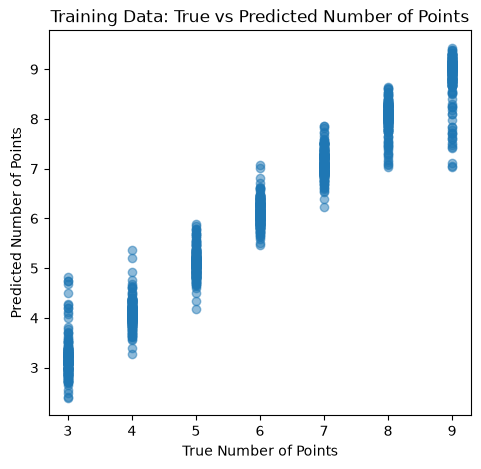

In [44]:
#evaluate

# try plotting predictions vs. targets for both training data and validation data in a scatterplot, and see how much variation you've captured
plt.figure(figsize=(12, 5))
# Training data
plt.subplot(1, 2, 1)
train_predictions = []
train_targets = []
for xbatch, ybatch in trainLoader:
    with torch.no_grad():
        output = net(xbatch)
    train_predictions.append(output.cpu().numpy())
    train_targets.append(ybatch.cpu().numpy())
train_predictions = np.concatenate(train_predictions, axis=0)
train_targets = np.concatenate(train_targets, axis=0)
plt.scatter(train_targets[:, 0], train_predictions[:, 0], alpha=0.5)
plt.xlabel('True Number of Points')
plt.ylabel('Predicted Number of Points')
plt.title('Training Data: True vs Predicted Number of Points')
